# Figure 6 | Background variation and state-conditioned gene prioritisation in E. coli

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display, Markdown

# evostate paths: data in data/manuscript, analysis code in notebooks/manuscript/lib,
# figures written to results/rendered/manuscript.
REPO = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'data/manuscript').is_dir() and (p / 'notebooks/manuscript/lib').is_dir()), None)
if REPO is None:
    raise FileNotFoundError('Start Jupyter inside the evostate repository.')
MANUSCRIPT_DATA = REPO / 'data/manuscript'
MANUSCRIPT_LIB = REPO / 'notebooks/manuscript/lib'
RENDERED = REPO / 'results/rendered/manuscript'
ROOT = REPO
DATA = MANUSCRIPT_DATA / 'ecoli2026/derived'
RESULTS = MANUSCRIPT_DATA / 'results_repr_evo'
MANUSCRIPT = RESULTS / 'manuscript'
FIVE = MANUSCRIPT / 'figure5'
STATE = RESULTS / 'ecoli2026_route_b/state_conditional'
EVAL = RESULTS / 'ecoli2026_route_b/endpoint/two_stage_temporal_inferred'
OUT = RENDERED / 'figure5'
OUT.mkdir(parents=True, exist_ok=True)
DRUGS = ['NIT', 'MEC', 'TMP']
COLOR = {'NIT': '#246bac', 'MEC': '#dc602b', 'TMP': '#278774'}
N_BOOT = 2000
SEED = 0
BIN_EDGES = [0, .2, .4, .6, .8, 1.]
BIN_MID = [10, 30, 50, 70, 90]
INPUTS = {}

def digest(path):
    h = hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def track(path):
    INPUTS[str(path.relative_to(ROOT))] = digest(path)
    return path

paired_manifest = json.loads(track(FIVE / 'figure5_paired_state_manifest.json').read_text())
for relative, expected in paired_manifest['inputs'].items():
    path = ROOT / relative
    if digest(track(path)) != expected:
        raise ValueError(f'Paired-analysis source changed: {relative}')
for key, expected in paired_manifest['outputs'].items():
    path = FIVE / f'figure5_paired_state_{key}.csv'
    if digest(track(path)) != expected:
        raise ValueError(f'Paired-analysis cache changed: {path.name}')
if paired_manifest['config']['evaluation'] != 'in_sample_inferred_transitions':
    raise ValueError('Review figure labels if evaluation provenance changes.')
PAIRED = pd.read_csv(FIVE / 'figure5_paired_state_items.csv')
PAIRED_SUMMARY = pd.read_csv(FIVE / 'figure5_paired_state_summary.csv')
if not PAIRED.evaluation.eq('in_sample_inferred_transitions').all():
    raise ValueError('Mixed evaluation provenance in paired ranks.')
ROLL_META = json.loads(track(STATE / 'rollout_meta.json').read_text())
if not ROLL_META.get('in_sample') or ROLL_META['top_k_curve'] != 5:
    raise ValueError('Unexpected reveal-cache provenance or candidate count.')
MATRIX, POPS, FEATURES, CURVES, CV = {}, {}, {}, {}, {}
for drug in DRUGS:
    MATRIX[drug] = pd.read_csv(track(DATA / 'endpoint' / drug / 'population_matrix.csv')).set_index('population_id')
    POPS[drug] = pd.read_csv(track(DATA / 'endpoint' / drug / 'populations.csv')).set_index('population_id')
    FEATURES[drug] = pd.read_csv(track(DATA / 'two_stage_temporal_inferred' / drug / 'feature_hierarchy.csv')).feature_id.astype(str).tolist()
    CURVES[drug] = pd.read_csv(track(STATE / f'rollout_curve_{drug}.csv'))
    CV[drug] = json.loads(track(EVAL / drug / 'eval/eval_summary.json').read_text())
    if not MATRIX[drug].index.is_unique or not POPS[drug].index.is_unique or set(MATRIX[drug].index) != set(POPS[drug].index):
        raise ValueError('Endpoint matrix and population metadata must match one-to-one.')
    if not np.isin(MATRIX[drug].to_numpy(), [0, 1]).all():
        raise ValueError('Endpoint matrix must be complete and binary.')
    POPS[drug] = POPS[drug].loc[MATRIX[drug].index]
    paired_drug = PAIRED[PAIRED.drug == drug]
    if not paired_drug.population_id.isin(POPS[drug].index).all():
        raise ValueError('Unknown population in paired predictions.')
print('Validated all input hashes, endpoint matrices and prediction-cache provenance.')


Validated all input hashes, endpoint matrices and prediction-cache provenance.


In [2]:
spectra, spectrum_stats = [], []
for drug in DRUGS:
    hits = MATRIX[drug].sum(axis=0).astype(int)
    frame = pd.DataFrame({'gene': hits.index, 'n_hit': hits.to_numpy()})
    frame = frame[frame.n_hit > 0].sort_values(['n_hit', 'gene'], ascending=[False, True]).reset_index(drop=True)
    frame['drug'] = drug
    frame['rank'] = np.arange(1, len(frame) + 1)
    frame['n_populations'] = len(MATRIX[drug])
    frame['frequency'] = frame.n_hit / len(MATRIX[drug])
    probabilities = frame.n_hit.to_numpy() / frame.n_hit.sum()
    entropy = float(-(probabilities * np.log2(probabilities)).sum())
    spectrum_stats.append(dict(drug=drug, n_populations=len(MATRIX[drug]), n_backgrounds=POPS[drug].background.nunique(), n_hit_genes=len(frame), entropy_bits=entropy, effective_genes=2 ** entropy, total_gene_hits=int(frame.n_hit.sum())))
    spectra.append(frame)
SPECTRA = pd.concat(spectra, ignore_index=True)
SPECTRUM_STATS = pd.DataFrame(spectrum_stats)

SPECTRUM_TOP_N = 100
SPECTRUM_LABEL_N = 6
REFERENCE_BG = 'lacA'
HEAT_GENES = SPECTRA[SPECTRA.drug == 'MEC'].head(20).gene.tolist()
heat_input = MATRIX['MEC'][HEAT_GENES].copy()
heat_input['background'] = POPS['MEC'].background
HEAT_COUNTS = heat_input.groupby('background')[HEAT_GENES].sum().astype(int)
HEAT_N = POPS['MEC'].groupby('background').size().reindex(HEAT_COUNTS.index)
heat_order = HEAT_COUNTS.sort_values(HEAT_GENES, ascending=False, kind='mergesort').index.tolist()
if REFERENCE_BG in heat_order:
    heat_order = [REFERENCE_BG] + [bg for bg in heat_order if bg != REFERENCE_BG]
HEAT_COUNTS = HEAT_COUNTS.loc[heat_order]
HEAT_N = HEAT_N.loc[heat_order]
HEAT = HEAT_COUNTS.div(HEAT_N, axis=0)
HEAT_SOURCE = HEAT.reset_index().melt(id_vars='background', var_name='gene', value_name='fraction_detected')
HEAT_SOURCE['n_sequenced'] = HEAT_SOURCE.background.map(HEAT_N)
HEAT_SOURCE['n_detected'] = np.rint(HEAT_SOURCE.fraction_detected * HEAT_SOURCE.n_sequenced).astype(int)
HEAT_SOURCE['row_order'] = HEAT_SOURCE.background.map({bg: i for i, bg in enumerate(HEAT.index)})
HEAT_SOURCE['column_order'] = HEAT_SOURCE.gene.map({gene: i for i, gene in enumerate(HEAT_GENES)})
SPECTRA.to_csv(OUT / 'figure6_source_a_gene_spectra.csv', index=False)
SPECTRUM_STATS.to_csv(OUT / 'figure6_source_a_diversity.csv', index=False)
HEAT_SOURCE.to_csv(OUT / 'figure6_source_b_background_composition.csv', index=False)
PAIRED.to_csv(OUT / 'figure6_source_cde_paired_ranks.csv', index=False)
PAIRED_SUMMARY.to_csv(OUT / 'figure6_source_cde_weighting_sensitivity.csv', index=False)
display(SPECTRUM_STATS.round(3))


,drug,n_populations,n_backgrounds,n_hit_genes,entropy_bits,effective_genes,total_gene_hits
0,NIT,106,35,285,7.443,174.024,1819
1,MEC,97,32,826,9.272,618.231,2258
2,TMP,108,35,1046,9.713,839.204,4154


In [3]:
long_frames, inclusion = [], []
for drug in DRUGS:
    curve = CURVES[drug].rename(columns={'group_id': 'population_id'}).copy()
    if not curve.drug.eq(drug).all() or curve.duplicated(['population_id', 'repeat', 'n_revealed']).any():
        raise ValueError('Drug mismatch or duplicated reveal records.')
    genes = [gene for gene in FEATURES[drug] if not gene.startswith('background__')]
    bg_known = {f[len('background__'):] for f in FEATURES[drug] if f.startswith('background__')}
    if not set(genes).issubset(MATRIX[drug].columns):
        raise ValueError('Unknown feature in reveal gene pool.')
    n_model_genes = MATRIX[drug][genes].sum(axis=1).astype(int)
    for pid, pop in POPS[drug].iterrows():
        reasons = []
        if str(pop.background) not in bg_known:
            reasons.append('background_not_encoded')
        if n_model_genes[pid] < 3:
            reasons.append('fewer_than_3_model_genes')
        if n_model_genes[pid] > 50:
            reasons.append('more_than_50_model_genes')
        inclusion.append(dict(drug=drug, population_id=pid, strain_group_id=str(pop.strain_group_id), background=str(pop.background), n_model_genes=int(n_model_genes[pid]), included=not reasons, reason=';'.join(reasons)))
    expected = {row['population_id'] for row in inclusion if row['drug'] == drug and row['included']}
    if set(curve.population_id) != expected:
        raise ValueError(f'{drug}: cached population selection differs from documented 3–50 gene rule.')
    if not curve.population_id.isin(POPS[drug].index).all():
        raise ValueError('Unknown reveal population.')
    curve['strain_group_id'] = curve.population_id.map(POPS[drug].strain_group_id)
    curve['background'] = curve.population_id.map(POPS[drug].background)
    curve['n_total'] = curve.population_id.map(n_model_genes)
    if not np.array_equal(curve.n_revealed + curve.n_remaining, curve.n_total):
        raise ValueError('Reveal and remaining counts do not match endpoint set size.')
    if not np.allclose(curve.frac_revealed, curve.n_revealed / curve.n_total):
        raise ValueError('Invalid revealed fraction.')
    for pid, population in curve.groupby('population_id'):
        if set(population['repeat']) != set(range(ROLL_META['repeats'])):
            raise ValueError('Incomplete random reveal replicates.')
        for _, repeat in population.groupby('repeat'):
            if set(repeat.n_revealed) != set(range(1, int(repeat.n_total.iloc[0]))):
                raise ValueError('Incomplete random reveal sequence.')
    curve['bin'] = pd.cut(curve.frac_revealed, BIN_EDGES, labels=BIN_MID, include_lowest=True).astype(int)
    denominator = np.minimum(5, curve.n_remaining.to_numpy())
    for method, col in [('EvoState', 'recall_evostate'), ('Frequency', 'recall_frequency')]:
        hits = curve[col].to_numpy() * denominator
        if not np.allclose(hits, np.rint(hits), atol=1e-7):
            raise ValueError('Cannot recover integer hits from overlap cache.')
        hits = np.rint(hits).astype(int)
        if np.any(hits < 0) or np.any(hits > denominator):
            raise ValueError('Hits outside feasible range.')
        frame = curve[['drug', 'population_id', 'strain_group_id', 'background', 'repeat', 'n_revealed', 'frac_revealed', 'n_remaining', 'n_total', 'bin']].copy()
        frame['method'] = method
        frame['hits'] = hits
        frame['normalized_overlap'] = hits / denominator
        frame['precision_at5'] = hits / 5.0
        frame['recall_at5'] = hits / curve.n_remaining.to_numpy()
        long_frames.append(frame)
REVEAL_RAW = pd.concat(long_frames, ignore_index=True)
INCLUSION = pd.DataFrame(inclusion)
REVEAL_METRICS = ['normalized_overlap', 'precision_at5', 'recall_at5']
repeat_bin = REVEAL_RAW.groupby(['drug', 'strain_group_id', 'population_id', 'repeat', 'bin', 'method'])[REVEAL_METRICS].mean().reset_index()
REVEAL_POP = repeat_bin.groupby(['drug', 'strain_group_id', 'population_id', 'bin', 'method'])[REVEAL_METRICS].mean().reset_index()
reveal_summaries, coverage = [], []
rng = np.random.default_rng(SEED)
for drug in DRUGS:
    valid = REVEAL_POP[REVEAL_POP.drug == drug]
    group_ids = sorted(valid.strain_group_id.unique())
    draws = rng.integers(0, len(group_ids), size=(N_BOOT, len(group_ids)))
    for bin_mid in BIN_MID:
        population_bin = valid[(valid.bin == bin_mid) & (valid.method == 'EvoState')]
        raw_bin = REVEAL_RAW[(REVEAL_RAW.drug == drug) & (REVEAL_RAW.bin == bin_mid) & (REVEAL_RAW.method == 'EvoState')]
        coverage.append(dict(drug=drug, bin=bin_mid, n_populations=population_bin.population_id.nunique(), n_groups=population_bin.strain_group_id.nunique(), n_rows=len(raw_bin), n_total_populations=valid.population_id.nunique(), median_remaining=float(raw_bin.n_remaining.median())))
    for (bin_mid, method), frame in valid.groupby(['bin', 'method']):
        for metric in REVEAL_METRICS:
            sums = frame.groupby('strain_group_id')[metric].sum().reindex(group_ids, fill_value=0).to_numpy()
            counts = frame.groupby('strain_group_id')[metric].count().reindex(group_ids, fill_value=0).to_numpy()
            den = counts[draws].sum(axis=1)
            boot = np.divide(sums[draws].sum(axis=1), den, out=np.full(N_BOOT, np.nan), where=den > 0)
            lo, hi = np.nanquantile(boot, [.025, .975])
            reveal_summaries.append(dict(drug=drug, bin=int(bin_mid), method=method, metric=metric, mean=float(frame[metric].mean()), ci_low=float(lo), ci_high=float(hi), n_populations=len(frame), n_groups=int((counts > 0).sum()), weighting='population_equal_after_repeat_bin_means', interval='strain_group_cluster_bootstrap_in_sample'))
REVEAL_SUMMARY = pd.DataFrame(reveal_summaries)
COVERAGE = pd.DataFrame(coverage)
for metric in REVEAL_METRICS:
    assert REVEAL_RAW[metric].between(0, 1).all()
assert not REVEAL_POP.duplicated(['drug', 'population_id', 'bin', 'method']).any()
REVEAL_RAW.to_csv(OUT / 'figure6_source_f_reveal_records.csv', index=False)
REVEAL_POP.to_csv(OUT / 'figure6_source_f_population_bins.csv', index=False)
REVEAL_SUMMARY.to_csv(OUT / 'figure6_source_f_cluster_intervals.csv', index=False)
COVERAGE.to_csv(OUT / 'figure6_source_f_bin_coverage.csv', index=False)
INCLUSION.to_csv(OUT / 'figure6_source_f_inclusion.csv', index=False)
display(REVEAL_SUMMARY[REVEAL_SUMMARY.metric == 'normalized_overlap'].pivot(index=['drug', 'bin'], columns='method', values='mean').round(3))
display(COVERAGE.pivot(index='drug', columns='bin', values='n_populations'))


method    EvoState  Frequency
drug bin                     
MEC  10      0.595      0.518
     30      0.599      0.472
     50      0.638      0.464
     70      0.606      0.454
     90      0.622      0.358
NIT  10      0.633      0.503
     30      0.711      0.544
     50      0.755      0.521
     70      0.783      0.527
     90      0.904      0.389
TMP  10      0.569      0.490
     30      0.574      0.467
     50      0.583      0.448
     70      0.624      0.459
     90      0.620      0.420

bin,10,30,50,70,90
drug,,,,,
MEC,69,82,74,82,50
NIT,26,67,43,67,21
TMP,72,87,80,87,58


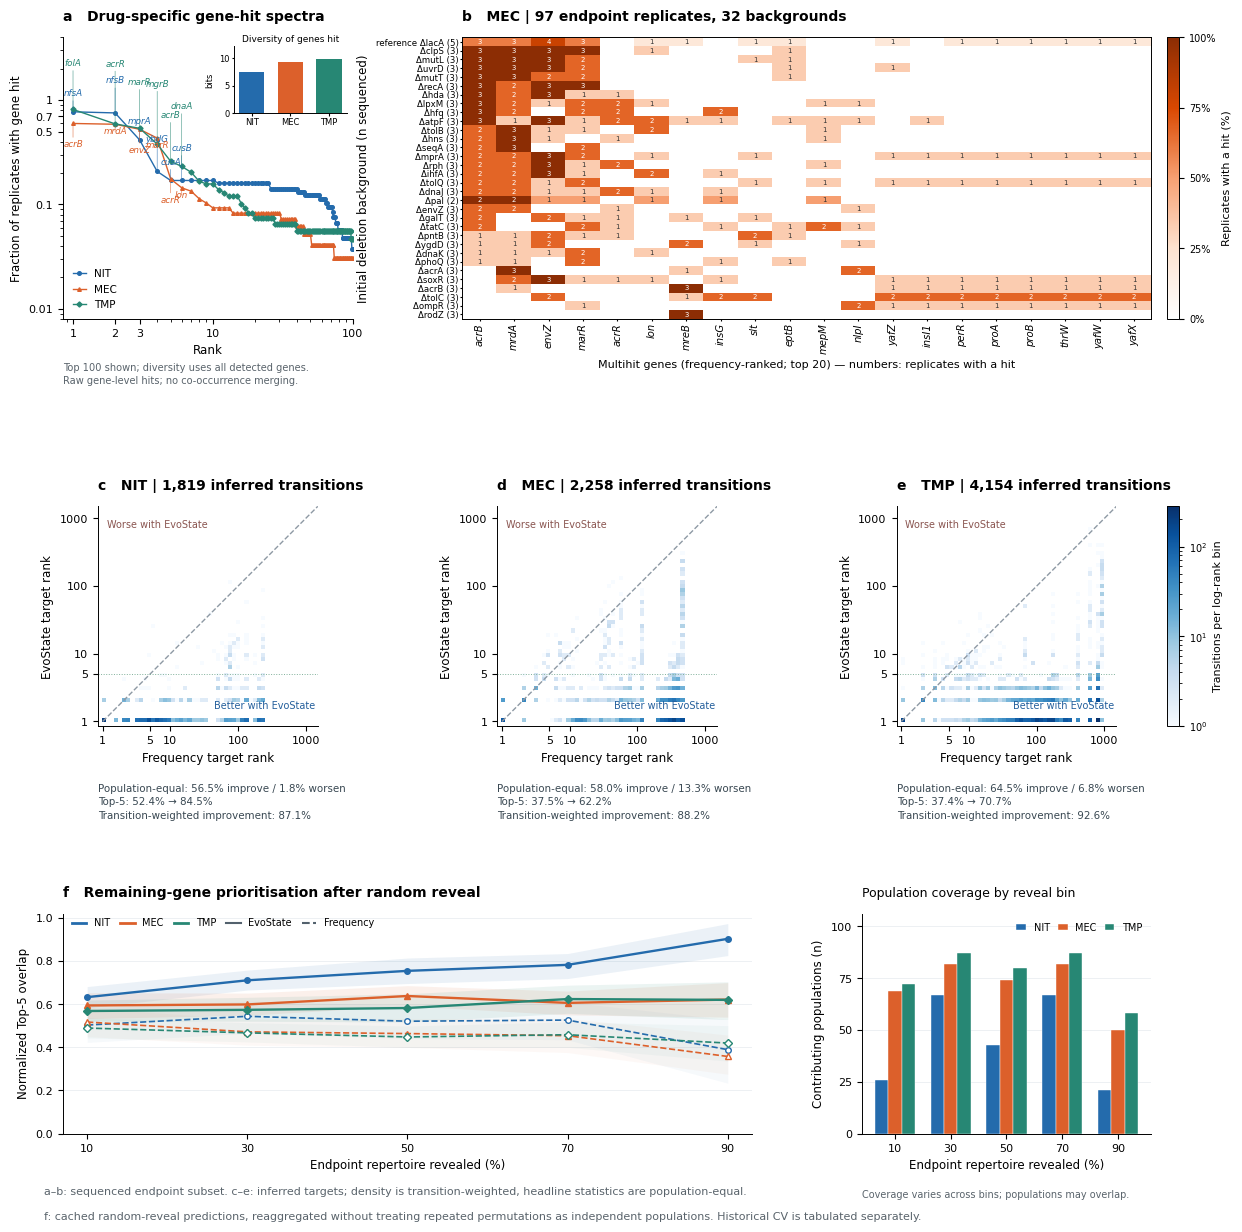

Main figure: /apdcephfs_qy3/share_2932069/ziyiyang/1-antibiotic_resistance/EvoAMR/evoamr/evostate/results/rendered/manuscript/figure5/figure5.png


In [4]:
RANK_LIMIT = max(1000, int(np.ceil(PAIRED.n_candidates.max() / 500) * 500))
RANK_EDGES = np.geomspace(.85, RANK_LIMIT, 55)
HIST = {drug: np.histogram2d(PAIRED.loc[PAIRED.drug == drug, 'rank_frequency'], PAIRED.loc[PAIRED.drug == drug, 'rank_evostate'], bins=[RANK_EDGES, RANK_EDGES])[0] for drug in DRUGS}
HIST_NORM = LogNorm(1, max(2, max(h.max() for h in HIST.values())))

def panel_title(ax, letter, title):
    ax.set_title(f'{letter}   {title}', loc='left', fontsize=10, fontweight='bold', pad=12)

def tidy(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=8)

def draw_spectrum(ax):
    markers = {'NIT': 'o', 'MEC': '^', 'TMP': 'D'}
    for drug in DRUGS:
        frame = SPECTRA[SPECTRA.drug == drug].head(SPECTRUM_TOP_N)
        ax.plot(frame['rank'], frame.frequency, marker=markers[drug], ms=2.6, color=COLOR[drug], lw=1.0, label=drug, zorder=3)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_ylim(.008, 4.0); ax.set_xlim(.85, SPECTRUM_TOP_N)
    ax.set_xticks([1, 2, 3, 10, 100]); ax.set_xticklabels(['1', '2', '3', '10', '100'])
    ax.set_yticks([.01, .1, .5, .7, 1]); ax.set_yticklabels(['0.01', '0.1', '0.5', '0.7', '1'])
    ax.set_xlabel('Rank', fontsize=8.5)
    ax.set_ylabel('Fraction of replicates with gene hit', fontsize=8.5)
    for drug, base_dy in [('NIT', 10), ('MEC', -12), ('TMP', 30)]:
        for i, row in enumerate(SPECTRA[SPECTRA.drug == drug].head(SPECTRUM_LABEL_N).itertuples()):
            dy = base_dy + (10 if i % 2 else 0)
            ax.annotate(row.gene, (row.rank, row.frequency), xytext=(0, dy), textcoords='offset points', ha='center', va='bottom' if dy > 0 else 'top', color=COLOR[drug], fontsize=6.3, style='italic', zorder=5, arrowprops=dict(arrowstyle='-', lw=.35, color=COLOR[drug], shrinkA=0, shrinkB=1.5))
    ax.legend(frameon=False, fontsize=7.5, loc='lower left', handlelength=1.3)
    inset = ax.inset_axes([.59, .73, .39, .24])
    entropy = SPECTRUM_STATS.set_index('drug').loc[DRUGS, 'entropy_bits'].to_numpy()
    inset.bar(np.arange(3), entropy, color=[COLOR[d] for d in DRUGS], width=.65)
    inset.set_xticks(np.arange(3), DRUGS, fontsize=6)
    inset.set_title('Diversity of genes hit', fontsize=6.5, pad=3)
    inset.set_ylabel('bits', fontsize=6)
    inset.set_ylim(0, max(entropy) * 1.25)
    inset.tick_params(labelsize=6, length=1.8, pad=1)
    inset.spines[['top', 'right']].set_visible(False)
    ax.text(0, -.23, 'Top 100 shown; diversity uses all detected genes.\nRaw gene-level hits; no co-occurrence merging.', transform=ax.transAxes, fontsize=7.1, color='#59636b', linespacing=1.4)
    panel_title(ax, 'a', 'Drug-specific gene-hit spectra')
    tidy(ax)

def draw_heatmap(ax):
    cmap = LinearSegmentedColormap.from_list('figure5_oranges', ['#ffffff', '#fde3d0', '#f7a072', '#d94801', '#8c2d04'])
    mesh = ax.imshow(HEAT.to_numpy(), cmap=cmap, vmin=0, vmax=1, aspect='auto', interpolation='nearest')
    for i in range(len(HEAT)):
        for j in range(len(HEAT_GENES)):
            count = int(HEAT_COUNTS.iloc[i, j])
            if count:
                ax.text(j, i, str(count), ha='center', va='center', fontsize=5.0, color='white' if HEAT.iloc[i, j] > .55 else '#333333')
    ax.set_yticks(range(len(HEAT)), [f'reference Δ{bg} ({HEAT_N[bg]})' if bg == REFERENCE_BG else f'Δ{bg} ({HEAT_N[bg]})' for bg in HEAT.index], fontsize=6.2)
    ax.set_xticks(range(len(HEAT_GENES)), HEAT_GENES, rotation=90, fontsize=7.2, style='italic')
    ax.tick_params(length=1.4, pad=1.5)
    ax.set_ylabel('Initial deletion background (n sequenced)', fontsize=8.5)
    ax.set_xlabel('Multihit genes (frequency-ranked; top 20) — numbers: replicates with a hit', fontsize=8, labelpad=4)
    panel_title(ax, 'b', f'MEC | {HEAT_N.sum()} endpoint replicates, {len(HEAT)} backgrounds')
    return mesh

def draw_ranks(ax, drug, letter):
    h = np.ma.masked_where(HIST[drug].T == 0, HIST[drug].T)
    mesh = ax.pcolormesh(RANK_EDGES, RANK_EDGES, h, cmap='Blues', norm=HIST_NORM, rasterized=True, shading='auto')
    ax.plot([1, RANK_LIMIT], [1, RANK_LIMIT], '--', color='#8e99a4', lw=1)
    ax.axhline(5, color='#80b09a', lw=.7, ls=':')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(.85, RANK_LIMIT); ax.set_ylim(.85, RANK_LIMIT)
    ax.set_aspect('equal')
    ax.set_xticks([1, 5, 10, 100, 1000]); ax.set_yticks([1, 5, 10, 100, 1000])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:g}'))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:g}'))
    ax.minorticks_off()
    ax.set_xlabel('Frequency target rank', fontsize=8.5)
    ax.set_ylabel('EvoState target rank', fontsize=8.5)
    n = len(PAIRED[PAIRED.drug == drug])
    panel_title(ax, letter, f'{drug} | {n:,} inferred transitions')
    ax.text(.04, .94, 'Worse with EvoState', transform=ax.transAxes, fontsize=7, va='top', color='#8a5550')
    ax.text(.53, .08, 'Better with EvoState', transform=ax.transAxes, fontsize=7, color='#245f9c')
    pop = PAIRED_SUMMARY[(PAIRED_SUMMARY.drug == drug) & (PAIRED_SUMMARY.weighting == 'population')].iloc[0]
    raw = PAIRED_SUMMARY[(PAIRED_SUMMARY.drug == drug) & (PAIRED_SUMMARY.weighting == 'transition')].iloc[0]
    ax.text(0, -.26, f'Population-equal: {pop.improved:.1%} improve / {pop.worsened:.1%} worsen\nTop-5: {pop.top5_frequency:.1%} → {pop.top5_evostate:.1%}\nTransition-weighted improvement: {raw.improved:.1%}', transform=ax.transAxes, fontsize=7.4, va='top', linespacing=1.45, color='#384751')
    tidy(ax)
    return mesh

def draw_completion(ax, metric='normalized_overlap', title=True):
    for drug in DRUGS:
        for method in ['EvoState', 'Frequency']:
            frame = REVEAL_SUMMARY[(REVEAL_SUMMARY.drug == drug) & (REVEAL_SUMMARY.metric == metric) & (REVEAL_SUMMARY.method == method)].sort_values('bin')
            x = frame.bin.to_numpy(dtype=float)
            solid = method == 'EvoState'
            ax.plot(x, frame['mean'].to_numpy(), color=COLOR[drug], ls='-' if solid else '--', marker={'NIT': 'o', 'MEC': '^', 'TMP': 'D'}[drug], ms=4, mfc=COLOR[drug] if solid else 'white', lw=1.7 if solid else 1.2, label=f'{drug} {method}')
            ax.fill_between(x, frame.ci_low.to_numpy(), frame.ci_high.to_numpy(), color=COLOR[drug], alpha=.09 if solid else .04, lw=0)
    ax.set_xticks(BIN_MID)
    ax.set_xlim(7, 93); ax.set_ylim(0, 1.02)
    ax.set_xlabel('Endpoint repertoire revealed (%)', fontsize=8.5)
    labels = {'normalized_overlap': 'Normalized Top-5 overlap', 'precision_at5': 'Precision@5 = hits / 5', 'recall_at5': 'Recall@5 = hits / remaining genes'}
    ax.set_ylabel(labels[metric], fontsize=8.5)
    ax.grid(axis='y', color='#edf0f3', lw=.7); ax.set_axisbelow(True)
    if title:
        panel_title(ax, 'f', 'Remaining-gene prioritisation after random reveal')
    tidy(ax)

with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 8, 'pdf.fonttype': 42, 'axes.linewidth': .7}):
    FIG = plt.figure(figsize=(12.8, 13.5), facecolor='white')
    grid = FIG.add_gridspec(3, 3, left=.085, right=.935, bottom=.09, top=.902, height_ratios=[1.28, 1, 1], hspace=.78, wspace=.38)
    draw_spectrum(FIG.add_subplot(grid[0, 0]))
    heat_ax = FIG.add_subplot(grid[0, 1:])
    heat_mesh = draw_heatmap(heat_ax)
    box = heat_ax.get_position()
    cb_heat = FIG.colorbar(heat_mesh, cax=FIG.add_axes([.947, box.y0, .010, box.height]))
    cb_heat.set_ticks([0, .25, .5, .75, 1.0])
    cb_heat.ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    cb_heat.set_label('Replicates with a hit (%)', fontsize=8)
    cb_heat.ax.tick_params(labelsize=7)
    rank_axes = []
    for j, drug in enumerate(DRUGS):
        rank_ax = FIG.add_subplot(grid[1, j]); rank_axes.append(rank_ax)
        rank_mesh = draw_ranks(rank_ax, drug, 'cde'[j])
    rank_box = rank_axes[-1].get_position()
    cb_rank = FIG.colorbar(rank_mesh, cax=FIG.add_axes([.947, rank_box.y0, .010, rank_box.height]))
    cb_rank.set_label('Transitions per log-rank bin', fontsize=8)
    cb_rank.ax.tick_params(labelsize=7)
    curve_ax = FIG.add_subplot(grid[2, :2])
    draw_completion(curve_ax)
    coverage_ax = FIG.add_subplot(grid[2, 2])
    coverage_table = COVERAGE.pivot(index='drug', columns='bin', values='n_populations').reindex(index=DRUGS, columns=BIN_MID)
    assert coverage_table.notna().all().all()
    xx = np.arange(len(BIN_MID))
    width = .24
    for j, drug in enumerate(DRUGS):
        counts = coverage_table.loc[drug].to_numpy(int)
        coverage_ax.bar(xx + (j - 1) * width, counts, width=width, color=COLOR[drug], label=drug, edgecolor='white', linewidth=.3)
    coverage_ax.set_xticks(xx, [str(int(v)) for v in BIN_MID])
    coverage_ax.set_xlabel('Endpoint repertoire revealed (%)', fontsize=8.5)
    coverage_ax.set_ylabel('Contributing populations (n)', fontsize=8.5)
    coverage_ax.set_title('Population coverage by reveal bin', fontsize=9, loc='left', pad=12)
    coverage_ax.set_ylim(0, coverage_table.to_numpy().max() * 1.22)
    coverage_ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=5, integer=True))
    coverage_ax.grid(axis='y', color='#edf0f3', linewidth=.7)
    coverage_ax.set_axisbelow(True)
    coverage_ax.legend(frameon=False, ncol=3, loc='upper right', fontsize=7, handlelength=1, columnspacing=.8)
    tidy(coverage_ax)
    handles = [Line2D([], [], color=COLOR[d], lw=2, label=d) for d in DRUGS]
    handles += [Line2D([], [], color='#53616d', lw=1.5, label='EvoState'), Line2D([], [], color='#53616d', lw=1.5, ls='--', label='Frequency')]
    curve_ax.legend(handles=handles, frameon=False, ncol=5, fontsize=7, loc='upper left', bbox_to_anchor=(0, 1.02), handlelength=1.5, columnspacing=1)
    coverage_ax.text(0, -.29, 'Coverage varies across bins; populations may overlap.', transform=coverage_ax.transAxes, fontsize=7, color='#59636b')
    coverage_table.to_csv(OUT / 'figure6_source_f_coverage_plot.csv')
    FIG.text(.07, .045, 'a–b: sequenced endpoint subset. c–e: inferred targets; density is transition-weighted, headline statistics are population-equal.', fontsize=8, color='#59636b')
    FIG.text(.07, .026, 'f: cached random-reveal predictions, reaggregated without treating repeated permutations as independent populations. Historical CV is tabulated separately.', fontsize=8, color='#59636b')
    for ext in ['pdf', 'png']:
        FIG.savefig(OUT / f'figure5.{ext}', dpi=240, bbox_inches='tight')
    display(FIG)
    plt.close(FIG)
print('Main figure:', OUT / 'figure5.png')


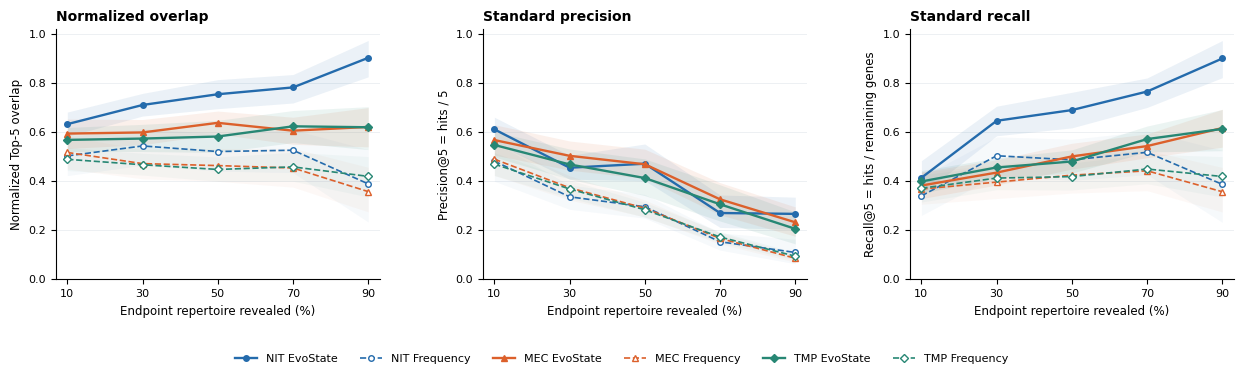

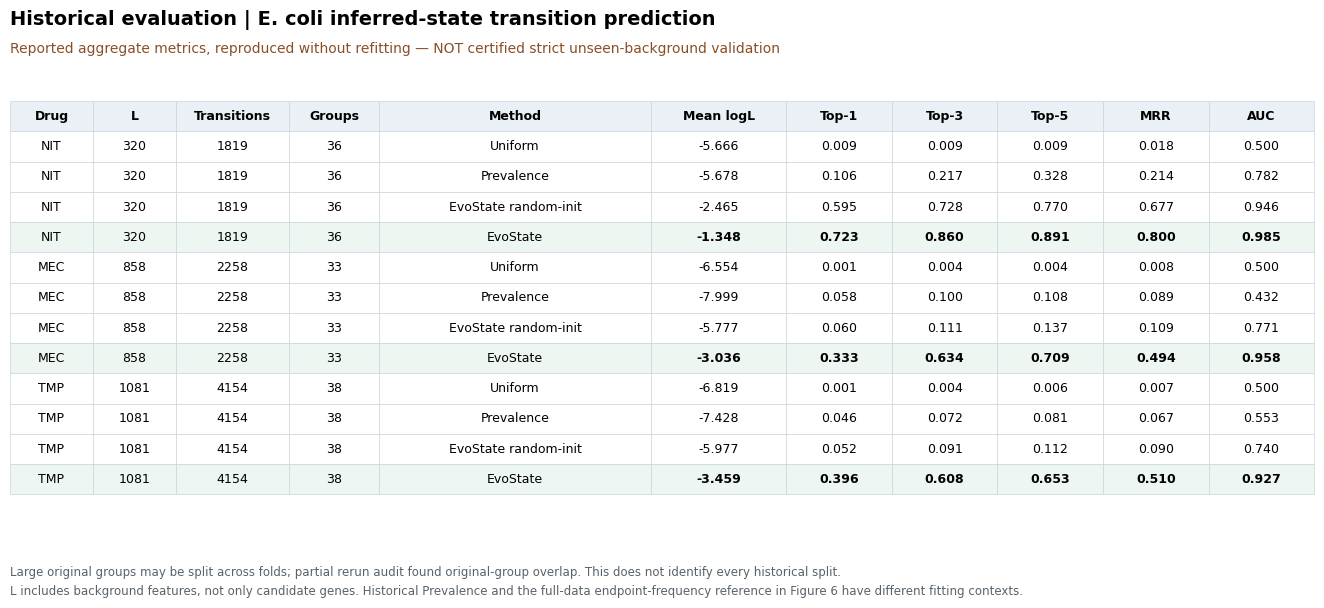

,drug,fold,n_overlapping_original_groups,overlap,source,scope
0,NIT,0,0,,data/manuscript/results_repr_evo/ecoli2026_rou...,partial_rerun_only_not_proof_of_all_historical...
1,NIT,1,2,NIT:E9_relA;NIT:F9_tolC,data/manuscript/results_repr_evo/ecoli2026_rou...,partial_rerun_only_not_proof_of_all_historical...
2,NIT,2,0,,data/manuscript/results_repr_evo/ecoli2026_rou...,partial_rerun_only_not_proof_of_all_historical...
3,NIT,3,1,NIT:F9_tolC,data/manuscript/results_repr_evo/ecoli2026_rou...,partial_rerun_only_not_proof_of_all_historical...
4,NIT,4,1,NIT:E9_relA,data/manuscript/results_repr_evo/ecoli2026_rou...,partial_rerun_only_not_proof_of_all_historical...


In [5]:
with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 8, 'pdf.fonttype': 42}):
    sensitivity, axes = plt.subplots(1, 3, figsize=(12.8, 4.1))
    for ax, metric in zip(axes, REVEAL_METRICS):
        draw_completion(ax, metric=metric, title=False)
        ax.set_title({'normalized_overlap': 'Normalized overlap', 'precision_at5': 'Standard precision', 'recall_at5': 'Standard recall'}[metric], loc='left', fontsize=10, fontweight='bold')
    handles, labels = axes[0].get_legend_handles_labels()
    sensitivity.legend(handles, labels, ncol=6, loc='lower center', frameon=False, fontsize=8)
    sensitivity.subplots_adjust(left=.06, right=.98, bottom=.22, top=.83, wspace=.32)
    for ext in ['png', 'pdf']:
        sensitivity.savefig(OUT / f'figure6_supplement_reveal_metrics.{ext}', dpi=220, bbox_inches='tight')
    display(sensitivity); plt.close(sensitivity)

METHODS = {'B0_uniform': 'Uniform', 'B1_prevalence': 'Prevalence', 'TS_random_init': 'EvoState random-init', 'TS_pretrained': 'EvoState'}
cv_rows = []
for drug in DRUGS:
    summary = CV[drug]
    for key, label in METHODS.items():
        metric = summary['overall'][key]
        cv_rows.append(dict(drug=drug, L=int(summary['L']), transitions=int(summary['n_transitions']), groups=int(summary['n_groups']), method=label, mean_logL=float(metric['mean_logl']), top1=float(metric['top1']), top3=float(metric['top3']), top5=float(metric['top5']), mrr=float(metric['mrr']), auc=float(metric['auc']), provenance='historical_grouped_eval_not_verified_strict_group_holdout'))
CV_TABLE = pd.DataFrame(cv_rows)
CV_TABLE.to_csv(OUT / 'figure6_historical_cv_table.csv', index=False)

fold_audit = []
for path in sorted((RESULTS / 'ecoli2026_route_b/endpoint/two_stage_temporal_inferred_bgholdout').glob('*/eval/fold_runs/*/holdout_groups.json')):
    record = json.loads(track(path).read_text())
    overlap = sorted(set(record['train_groups']) & set(record['holdout_groups']))
    fold_audit.append(dict(drug=path.parents[3].name, fold=int(record['fold']), n_overlapping_original_groups=len(overlap), overlap=';'.join(overlap), source=str(path.relative_to(ROOT)), scope='partial_rerun_only_not_proof_of_all_historical_splits'))
FOLD_AUDIT = pd.DataFrame(fold_audit, columns=['drug', 'fold', 'n_overlapping_original_groups', 'overlap', 'source', 'scope'])
FOLD_AUDIT.to_csv(OUT / 'figure6_partial_rerun_fold_audit.csv', index=False)

columns = ['drug', 'L', 'transitions', 'groups', 'method', 'mean_logL', 'top1', 'top3', 'top5', 'mrr', 'auc']
cell_values = []
for row in CV_TABLE.itertuples(index=False):
    cell_values.append([row.drug, str(row.L), str(row.transitions), str(row.groups), row.method, f'{row.mean_logL:.3f}', f'{row.top1:.3f}', f'{row.top3:.3f}', f'{row.top5:.3f}', f'{row.mrr:.3f}', f'{row.auc:.3f}'])
with plt.rc_context({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42}):
    table_fig, ax = plt.subplots(figsize=(13.8, 6.3)); ax.axis('off')
    table_fig.text(.035, .94, 'Historical evaluation | E. coli inferred-state transition prediction', fontsize=14, fontweight='bold')
    table_fig.text(.035, .895, 'Reported aggregate metrics, reproduced without refitting — NOT certified strict unseen-background validation', fontsize=10, color='#8a4f28')
    t = ax.table(cellText=cell_values, colLabels=['Drug', 'L', 'Transitions', 'Groups', 'Method', 'Mean logL', 'Top-1', 'Top-3', 'Top-5', 'MRR', 'AUC'], colWidths=[.055, .055, .075, .06, .18, .09, .07, .07, .07, .07, .07], cellLoc='center', bbox=[0, .12, 1, .79])
    t.auto_set_font_size(False); t.set_fontsize(9)
    for (r, c), cell in t.get_celld().items():
        cell.set_linewidth(.5); cell.set_edgecolor('#cbd5df')
        if r == 0:
            cell.set_facecolor('#eaf0f5'); cell.get_text().set_weight('bold')
        elif CV_TABLE.iloc[r - 1]['method'] == 'EvoState':
            cell.set_facecolor('#eef6f2')
            if c >= 5:
                cell.get_text().set_weight('bold')
    table_fig.text(.035, .065, 'Large original groups may be split across folds; partial rerun audit found original-group overlap. This does not identify every historical split.', fontsize=8.5, color='#59636b')
    table_fig.text(.035, .035, 'L includes background features, not only candidate genes. Historical Prevalence and the full-data endpoint-frequency reference in Figure 6 have different fitting contexts.', fontsize=8.5, color='#59636b')
    table_fig.subplots_adjust(left=.035, right=.98, top=.89, bottom=.10)
    for ext in ['png', 'pdf']:
        table_fig.savefig(OUT / f'figure6_historical_cv_table.{ext}', dpi=200, bbox_inches='tight')
    display(table_fig); plt.close(table_fig)
display(FOLD_AUDIT)


In [6]:
assert len(PAIRED) == sum(CV[d]['n_transitions'] for d in DRUGS)
assert not PAIRED.duplicated(['drug', 'row_id']).any()
assert (PAIRED[['improved', 'tied', 'worsened']].sum(axis=1) == 1).all()
for drug in DRUGS:
    assert int(HIST[drug].sum()) == int((PAIRED.drug == drug).sum())
    for method in ['evostate', 'frequency']:
        assert PAIRED.loc[PAIRED.drug == drug, f'top5_{method}'].between(0, 1).all()
assert np.allclose(REVEAL_RAW.precision_at5 * 5, REVEAL_RAW.hits)
assert np.allclose(REVEAL_RAW.recall_at5 * REVEAL_RAW.n_remaining, REVEAL_RAW.hits)
assert np.allclose(REVEAL_RAW.normalized_overlap * np.minimum(5, REVEAL_RAW.n_remaining), REVEAL_RAW.hits)
assert HEAT_SOURCE.fraction_detected.between(0, 1).all()
assert np.allclose(HEAT_SOURCE.fraction_detected, HEAT_SOURCE.n_detected / HEAT_SOURCE.n_sequenced)

report = []
for drug in DRUGS:
    pop = PAIRED_SUMMARY[(PAIRED_SUMMARY.drug == drug) & (PAIRED_SUMMARY.weighting == 'population')].iloc[0]
    for bin_mid in [10, 90]:
        ss = REVEAL_SUMMARY[(REVEAL_SUMMARY.drug == drug) & (REVEAL_SUMMARY.bin == bin_mid) & (REVEAL_SUMMARY.metric == 'normalized_overlap')].set_index('method')
        report.append(dict(drug=drug, reveal_bin=bin_mid, paired_top5_frequency=pop.top5_frequency, paired_top5_evostate=pop.top5_evostate, paired_population_improved=pop.improved, completion_frequency=ss.loc['Frequency', 'mean'], completion_evostate=ss.loc['EvoState', 'mean'], completion_difference=ss.loc['EvoState', 'mean'] - ss.loc['Frequency', 'mean'], n_populations=int(ss.loc['EvoState', 'n_populations'])))
REPORT = pd.DataFrame(report)
REPORT.to_csv(OUT / 'figure6_quotable_numbers.csv', index=False)
exported = sorted(p for p in OUT.iterdir() if p.is_file() and p.name not in {'figure6_manifest.json', 'execution.log'})
manifest = {'figure': 6, 'seed': SEED, 'cluster_bootstrap_repeats': N_BOOT, 'inputs': INPUTS, 'outputs': {p.name: digest(p) for p in exported}, 'model_evaluation': 'all-data fit / in-sample', 'excluded_panels': ['single-case explanations', 'random-reveal path trees', 'autonomous paths'], 'completion_metric': 'hits/min(5,remaining)', 'completion_weighting': 'step_within_repeat_bin_then_repeats_then_equal_population', 'completion_intervals': 'strain_group_cluster_bootstrap_descriptive', 'completion_population_rule': '3–50 model genes; not biological hypermutator status', 'completion_candidate_mask': 'inherited cache: acquired genes masked; deleted gene not additionally masked', 'paired_candidate_mask': 'acquired and deleted genes excluded', 'source_cache_limitation': 'paired cache hashes verified; reveal cache has no original checkpoint hash, only declared all-data source and current file digest', 'historical_cv_status': 'grouped label does not ensure strict original-group holdout; partial rerun audited separately', 'displayed_samples_change_with_reveal_bin': True}
(OUT / 'figure6_manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
display(REPORT.round(4))
print('Validation passed. Main figure:', OUT / 'figure5.png')
print('PDF:', OUT / 'figure5.pdf')
print('Source data, statistical sensitivity, historical table and manifest:', OUT)


,drug,reveal_bin,paired_top5_frequency,paired_top5_evostate,paired_population_improved,completion_frequency,completion_evostate,completion_difference,n_populations
0,NIT,10,0.5237,0.8447,0.5653,0.5035,0.6330,0.1296,26
1,NIT,90,0.5237,0.8447,0.5653,0.3893,0.9036,0.5142,21
2,MEC,10,0.3745,0.6215,0.5798,0.5175,0.5945,0.0770,69
3,MEC,90,0.3745,0.6215,0.5798,0.3578,0.6217,0.2639,50
4,TMP,10,0.3740,0.7070,0.6446,0.4896,0.5687,0.0791,72
5,TMP,90,0.3740,0.7070,0.6446,0.4199,0.6203,0.2004,58


Validation passed. Main figure: /apdcephfs_qy3/share_2932069/ziyiyang/1-antibiotic_resistance/EvoAMR/evoamr/evostate/results/rendered/manuscript/figure5/figure5.png
PDF: /apdcephfs_qy3/share_2932069/ziyiyang/1-antibiotic_resistance/EvoAMR/evoamr/evostate/results/rendered/manuscript/figure5/figure5.pdf
Source data, statistical sensitivity, historical table and manifest: /apdcephfs_qy3/share_2932069/ziyiyang/1-antibiotic_resistance/EvoAMR/evoamr/evostate/results/rendered/manuscript/figure5
